<div style="text-align:center;"> 
<h1 style="color:#D90257; font-family:'Georgia', serif;">
<u>1- Pipeline de Nettoyage — Analyse de Sentiment en Darija</u>
</h1>
</div>

<div style="text-align:center;">
<h2 style="color:#FFA3DF; font-family:'Trebuchet MS', sans-serif;">

**Étudiantes : Ihsane Foudal** 

**Kadidiatou DEM**
 
**IID2**  


</h2>
</div>Pipeline de Nettoyage — Analyse de Sentiment en Darija

**Projet :** Analyse de sentiment de commentaires YouTube & Instagram en Darija marocain  
**Étape :** Prétraitement et nettoyage des données

---

## 📋 Vue d'ensemble du pipeline

| Phase | Titre | Opérations principales |
|:-----:|-------|------------------------|
| **1** | Audit initial des données | Chargement, valeurs manquantes, doublons, statistiques |
| **2** | Suppression du bruit non textuel | Emojis seuls, chiffres, ponctuation, rires arabes, URLs, mentions |
| **3** | Filtrage linguistique Darija | Détection Darija vs MSA, vocabulaires spécialisés, liste noire |
| **4** | Normalisation & Tokenisation | Minuscules, diacritiques, tokenisation, suppression stopwords |
| **5** | Récupération des emojis | Réintégration des emojis depuis le dataset brut |

---

### 📁 Fichiers utilisés

| Fichier | Rôle |
|---------|------|
| `last_comments_brutes.json` | Dataset source brut (lecture seule) |
| `cleaned_step_autre.json` | Dataset de travail (mis à jour à chaque phase) |
| `fichier_fusionne_final_DN_latin.csv` | Lexique Darija (arabe + latin) |
| `msa_words_2.csv` | Dictionnaire MSA général |
| `mmssa_pur.csv` | Dictionnaire MSA élargi |
| `mot_msa_pur.csv` | Dictionnaire MSA complémentaire |
| `stopwords_darija_large.csv` | Stopwords Darija (arabe + latin) |
| `cleaned_with_emoji.json` | Dataset final avec emojis réintégrés |

> ⚠️ **Règle absolue :** Le fichier source brut `last_comments_brutes.json` ne sera **jamais modifié**.

---
---

# 📦 PHASE 1 — Audit Initial des Données

## Objectif

Avant d'appliquer tout traitement, nous devons analyser l'état brut du dataset afin de :
- Connaître le nombre total de commentaires collectés
- Identifier les colonnes disponibles et leur contenu
- Détecter et supprimer les entrées corrompues ou inutilisables
- Éliminer les doublons qui fausseraient l'analyse

Cette phase est le **point de départ obligatoire** du pipeline. Elle garantit que les phases suivantes travaillent sur des données saines et non redondantes.

---

### 🔧 Étape 1.1 — Import des librairies

On importe les bibliothèques Python nécessaires pour cette phase :
- `json` : lecture et écriture des fichiers JSON
- `pandas` : manipulation et analyse des données sous forme de DataFrame
- `pathlib.Path` : gestion des chemins de fichiers de manière portable
- `IPython.display` : affichage enrichi dans le notebook

In [49]:
import json
import pandas as pd
from pathlib import Path

### 📂 Étape 1.2 — Chargement du fichier brut

On charge le fichier JSON brut contenant tous les commentaires collectés depuis YouTube et Instagram.  
Le fichier est converti en `DataFrame` pandas pour faciliter l'analyse.

> 🔒 **Important :** Ce fichier est ouvert en lecture uniquement. Aucune modification ne sera apportée au fichier source.

In [ ]:
# Chemin vers le fichier brut
raw_path = Path("../data_collect/last_comments_brutes.json")

# Chargement du JSON
with open(raw_path, "r", encoding="utf-8") as f:
    raw_data = json.load(f)

# Conversion en DataFrame pour faciliter l’analyse
df = pd.DataFrame(raw_data)

print("Fichier chargé avec succès ✅")
print(f"Nombre total de commentaires bruts : {len(df)}")

Fichier chargé avec succès ✅
Nombre total de commentaires bruts : 70514


### 👁️ Étape 1.3 — Aperçu des données brutes

On affiche les 5 premières lignes du dataset pour avoir une vue rapide du contenu et du format des données. Cela permet de vérifier que le chargement s'est bien effectué et d'identifier la structure des commentaires (colonnes disponibles, exemples de textes, etc.).

In [51]:
df.head()

,comment_id,text,likes,date
0,17966659179020106,احمل ممثلة مغربية ❤️,13,2026-03-01T01:19:52.000Z
1,17963219130045803,😍😍😍😍😍😍😍,5,2026-03-01T00:11:00.000Z
2,17966804126994760,والله ايلا حتى انا جبت 0.50. Hhhhhhh,57,2026-03-01T02:02:38.000Z
3,17949552534103813,جبت حتى أنا بحالك ولكن الحمدلله نقط الأخرين.نق...,22,2026-03-01T02:31:52.000Z
4,18078505571599383,@youssefhac @ham__zaaa007 machi bu7dkom li j...,4,2026-03-01T04:25:50.000Z


### 🏷️ Étape 1.4 — Vérification des colonnes disponibles

On liste toutes les colonnes présentes dans le dataset brut. Cette vérification permet de s'assurer que les colonnes essentielles sont bien présentes, notamment :
- `text` : le contenu textuel du commentaire
- `comment_id` : l'identifiant unique de chaque commentaire

In [52]:
print("Colonnes présentes dans le dataset :")
print(df.columns)

Colonnes présentes dans le dataset :
Index(['comment_id', 'text', 'likes', 'date'], dtype='object')


### 🔍 Étape 1.5 — Vérification des valeurs manquantes

On compte le nombre de valeurs `NaN` (nulles) par colonne. Les valeurs manquantes dans la colonne `text` sont particulièrement problématiques car elles représentent des commentaires sans contenu — ils doivent être supprimés avant tout traitement.

In [53]:
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())

Valeurs manquantes par colonne :
comment_id    0
text          0
likes         0
date          0
dtype: int64


### 🗑️ Étape 1.6 — Suppression des textes vides ou nuls

On supprime toutes les entrées dont le champ `text` est inutilisable, c'est-à-dire :
- Les valeurs `None` ou `NaN` (champs complètement vides)
- Les chaînes de caractères vides `""`
- Les textes composés uniquement d'espaces (ex : `"   "`)

Ces entrées ne contiennent aucune information linguistique et ne peuvent pas être traitées.

In [54]:
# Nombre avant suppression
before = len(df)

# Supprimer les NaN
df = df.dropna(subset=["text"])

# Supprimer textes vides ou espaces
df = df[df["text"].str.strip() != ""]

after = len(df)

print(f"Commentaires supprimés (vides ou NaN) : {before - after}")
print(f"Commentaires restants : {after}")

Commentaires supprimés (vides ou NaN) : 103
Commentaires restants : 70411


### 🔁 Étape 1.7 — Suppression des doublons par identifiant (comment_id)

Lors de la collecte de données sur plusieurs périodes ou sources, un même commentaire peut avoir été enregistré plusieurs fois avec le même `comment_id`. On ne conserve que la **première occurrence** de chaque identifiant unique afin d'éviter de compter plusieurs fois le même commentaire dans l'analyse.

In [55]:
before = len(df)

df = df.drop_duplicates(subset=["comment_id"])

after = len(df)

print(f"Doublons supprimés (comment_id) : {before - after}")
print(f"Commentaires restants : {after}")

Doublons supprimés (comment_id) : 0
Commentaires restants : 70411


### 🔁 Étape 1.8 — Suppression des doublons par contenu textuel

Certains commentaires peuvent avoir des `comment_id` différents mais un **texte identique** (par exemple, des bots ou des copier-coller). On applique une deuxième déduplication basée sur le contenu textuel afin de garantir l'unicité de chaque commentaire dans le dataset.

In [56]:
before = len(df)

df = df.drop_duplicates(subset=["text"])

after = len(df)

print(f"Doublons supprimés (text identique) : {before - after}")
print(f"Commentaires restants : {after}")

Doublons supprimés (text identique) : 13560
Commentaires restants : 56851


### 📊 Étape 1.9 — Statistiques générales du dataset

On génère un résumé statistique complet du dataset après audit. Cette vue d'ensemble permet d'évaluer la qualité globale des données et de repérer d'éventuelles anomalies supplémentaires avant de passer aux phases de nettoyage.

In [57]:
from IPython.display import display

print("Résumé statistique :")
display(df.describe(include="all").round(2))

Résumé statistique :


,comment_id,text,likes,date
count,56851,56851,56851.00,56851
unique,56851,56851,NaN,55242
top,17966659179020106,احمل ممثلة مغربية ❤️,NaN,2026-01-20T19:18:03Z
freq,1,1,NaN,13
mean,NaN,NaN,3.76,NaN
std,NaN,NaN,80.15,NaN
min,NaN,NaN,0.00,NaN
25%,NaN,NaN,0.00,NaN
50%,NaN,NaN,0.00,NaN
75%,NaN,NaN,1.00,NaN


### 💾 Étape 1.10 — Sauvegarde du dataset après Phase 1

Le dataset nettoyé (sans valeurs manquantes ni doublons) est sauvegardé dans le fichier `cleaned_step_autre.json`. Ce fichier sera le point de départ de toutes les phases suivantes du pipeline.

In [58]:
clean_step1_path = Path("cleaned_step_autre.json")

df.to_json(clean_step1_path, orient="records", force_ascii=False, indent=4,date_format="iso")

print("Fichier cleaned_step_autre.json sauvegardé avec succès ✅")

Fichier cleaned_step_autre.json sauvegardé avec succès ✅


### ✅ Étape 1.11 — Vérification finale de la Phase 1

On recharge le fichier sauvegardé et on effectue une **vérification automatique** pour s'assurer que toutes les opérations de la Phase 1 ont été appliquées correctement :
- Absence de valeurs manquantes
- Absence de textes vides
- Absence de doublons par `comment_id`
- Absence de doublons textuels

Un aperçu aléatoire de 5 commentaires est affiché pour un contrôle visuel rapide.

In [59]:
# ==========================================
# VERIFICATION COMPLETE - PHASE 1
# ==========================================

from pathlib import Path
import pandas as pd

print("="*60)
print("VERIFICATION DU FICHIER cleaned_step_autre.json")
print("="*60)

# Chargement
clean_path = Path("cleaned_step_autre.json")
df = pd.read_json(clean_path)

total_comments = len(df)

# Vérifications
missing_values = df.isnull().sum().sum()
empty_texts = df[df["text"].str.strip() == ""].shape[0]
duplicate_ids = df.duplicated(subset=["comment_id"]).sum()
duplicate_texts = df.duplicated(subset=["text"]).sum()

# Affichage résumé
print(f"\nNombre total de commentaires : {total_comments}")
print("-"*60)
print(f"Valeurs manquantes totales : {missing_values}")
print(f"Textes vides restants : {empty_texts}")
print(f"Doublons par comment_id : {duplicate_ids}")
print(f"Doublons par texte : {duplicate_texts}")
print("-"*60)

# Validation finale
if (missing_values == 0 and 
    empty_texts == 0 and 
    duplicate_ids == 0 and 
    duplicate_texts == 0):
    
    print("✅ PHASE 1 VALIDEE : Dataset propre et prêt pour Phase 2.")
else:
    print("❌ PROBLEME DETECTE : Nettoyage incomplet.")
    
print("="*60)

# Aperçu aléatoire pour contrôle visuel
print("\nAperçu aléatoire de 5 commentaires :\n")
display(df.sample(5))

VERIFICATION DU FICHIER cleaned_step_autre.json

Nombre total de commentaires : 56851
------------------------------------------------------------
Valeurs manquantes totales : 0
Textes vides restants : 0
Doublons par comment_id : 0
Doublons par texte : 0
------------------------------------------------------------
✅ PHASE 1 VALIDEE : Dataset propre et prêt pour Phase 2.

Aperçu aléatoire de 5 commentaires :



,comment_id,text,likes,date
41113,UgxlURTN20iUyAzzj4l4AaABAg,ممكن يكون منتخبنا احسن في للمقابلة القادمة و ...,1,2026-01-06 01:28:41+00:00
37823,UgymdDA1BtBYUcxIqYJ4AaABAg,عمرني بكيت على شي ماتش فحياتي تال لهادا الله ي...,2,2026-01-19 16:32:51+00:00
46866,UgyZqDMrp42VO0sfn2N4AaABAg,ايكامان مضروب ما عرفوش امتى غادي يكون جاهز,0,2025-12-11 20:18:53+00:00
51598,Ugz_Zv2rU6b7zA2W8cp4AaABAg,Makentsh baghi nboul f tiran walakin belt,0,2026-01-08 23:28:43+00:00
31308,UgzC7GBao3SPsX_EQe14AaABAg,اقسم بالله الى جبت واليدينا عندي هاد العام لاو...,0,2025-08-01 18:32:20+00:00


---
---

# 🔇 PHASE 2 — Suppression du Bruit Non Textuel

## Objectif

Cette phase vise à éliminer tous les commentaires qui **ne contiennent aucune information linguistique exploitable** pour l'analyse de sentiment. Un commentaire composé uniquement d'emojis, de chiffres ou de ponctuation ne peut pas être analysé en termes de sentiment.

Cette phase se déroule en **deux temps** :

1. **Suppression des commentaires entièrement bruités** (emojis seuls, chiffres seuls, ponctuation seule, rires arabes répétitifs, textes trop courts)
2. **Nettoyage interne des textes** : suppression des URLs, mentions, hashtags, emojis intégrés et caractères spéciaux qui se trouvent *dans* les commentaires conservés

Toutes les opérations sont réalisées à l'aide d'**expressions régulières (regex)**.

---

## Partie 2A — Suppression des Commentaires Entièrement Bruités

### 📂 Étape 2.1 — Chargement du dataset après Phase 1

On charge le fichier `cleaned_step_autre.json` produit en Phase 1. On enregistre le nombre initial de commentaires pour calculer les statistiques de suppression à la fin de cette phase.

In [60]:
import pandas as pd
import re
from pathlib import Path

file_path = Path("cleaned_step_autre.json")
df = pd.read_json(file_path)

initial_count = len(df)

print(f"Nombre initial de commentaires : {initial_count}")

Nombre initial de commentaires : 56851


### 😀 Étape 2.2 — Suppression des commentaires composés uniquement d'emojis

Un commentaire est considéré comme du **bruit pur** s'il ne contient que des caractères non alphanumériques (emojis, symboles). Ce type de commentaire — par exemple `❤️🔥😂` — ne contient aucun mot et est donc inutilisable pour l'analyse de sentiment.

On utilise un `fullmatch` avec le pattern `[^\w\s]+` qui détecte les chaînes composées **entièrement** de caractères non-mot.

In [61]:
emoji_mask = df["text"].str.fullmatch(r"[^\w\s]+")
emoji_count = emoji_mask.sum()

print(f"Commentaires uniquement emojis détectés : {emoji_count}")

df = df[~emoji_mask]

print(f"Commentaires restants après suppression emojis : {len(df)}")

Commentaires uniquement emojis détectés : 2408
Commentaires restants après suppression emojis : 54443


### 🔢 Étape 2.3 — Suppression des commentaires composés uniquement de chiffres

Les commentaires ne contenant que des chiffres (ex : `12345`, `2024`) ne portent aucun sens linguistique et ne peuvent pas être interprétés comme un sentiment positif ou négatif. On les supprime via un `fullmatch` avec le pattern `\d+`.

In [62]:
digits_mask = df["text"].str.fullmatch(r"\d+")
digits_count = digits_mask.sum()

print(f"Commentaires uniquement chiffres détectés : {digits_count}")

df = df[~digits_mask]

print(f"Commentaires restants après suppression chiffres : {len(df)}")

Commentaires uniquement chiffres détectés : 33
Commentaires restants après suppression chiffres : 54410


### ❗ Étape 2.4 — Suppression des commentaires composés uniquement de ponctuation

Les commentaires comme `!!!`, `.....`, `???` sont fréquents sur les réseaux sociaux mais ne contiennent aucun contenu textuel exploitable. On les identifie grâce à un pattern ciblant uniquement les caractères de ponctuation courants.

In [63]:
punct_mask = df["text"].str.fullmatch(r"[.,!?;:()\-_\"]+")
punct_count = punct_mask.sum()

print(f"Commentaires uniquement ponctuation détectés : {punct_count}")

df = df[~punct_mask]

print(f"Commentaires restants après suppression ponctuation : {len(df)}")

Commentaires uniquement ponctuation détectés : 0
Commentaires restants après suppression ponctuation : 54410


### 😂 Étape 2.5 — Suppression des rires arabes répétitifs isolés

En Darija, le rire est souvent exprimé par la répétition de la lettre arabe `ه` (ex : `ههههههه`). Lorsqu'un commentaire ne contient **que** ces répétitions (3 fois ou plus), il ne porte pas de sentiment clair et exploitable. On le considère donc comme du bruit et on le supprime.

In [64]:
laugh_mask = df["text"].str.strip().str.fullmatch(r"(ه\s*){3,}")
laugh_count = laugh_mask.sum()

print(f"Rires arabes isolés détectés : {laugh_count}")

df = df[~laugh_mask]

print(f"Commentaires restants après suppression rires isolés : {len(df)}")

Rires arabes isolés détectés : 11
Commentaires restants après suppression rires isolés : 54399


### ✂️ Étape 2.6 — Suppression des commentaires trop courts (moins de 2 mots)

Un commentaire composé d'un seul mot (ex : `xx`, `ok`, `ah`) est généralement **ambigu** et peu informatif pour l'analyse de sentiment. Sans contexte, il est impossible de déterminer s'il est positif, négatif ou neutre. On supprime donc tous les commentaires contenant strictement moins de 2 mots.

In [65]:
short_mask = df["text"].str.split().apply(len) < 2
short_count = short_mask.sum()

print(f"Commentaires trop courts détectés : {short_count}")

df = df[~short_mask]

print(f"Commentaires restants après suppression textes courts : {len(df)}")

Commentaires trop courts détectés : 1720
Commentaires restants après suppression textes courts : 52679


### 📊 Étape 2.7 — Résumé global de la suppression du bruit

On calcule le bilan complet de la Partie 2A : nombre total de commentaires supprimés, pourcentage de bruit éliminé et nombre de commentaires restants pour la suite du pipeline.

In [66]:
final_count = len(df)
removed = initial_count - final_count
percentage = (removed / initial_count) * 100

print("="*60)
print("RESULTAT GLOBAL PHASE 2")
print("="*60)
print(f"Total supprimé : {removed}")
print(f"Pourcentage supprimé : {percentage:.2f}%")
print(f"Commentaires restants : {final_count}")
print("="*60)

RESULTAT GLOBAL PHASE 2
Total supprimé : 4172
Pourcentage supprimé : 7.34%
Commentaires restants : 52679


### 💾 Étape 2.8 — Sauvegarde après suppression du bruit

On met à jour le fichier de travail `cleaned_step_autre.json` avec le dataset nettoyé de tous les commentaires entièrement bruités.

In [67]:
df.to_json(file_path, orient="records", force_ascii=False, indent=4,date_format="iso")
print("Fichier cleaned_step_autre.json mis à jour avec succès ✅")

Fichier cleaned_step_autre.json mis à jour avec succès ✅


---

## Partie 2B — Nettoyage Interne du Texte (URLs, Mentions, Emojis, Caractères Spéciaux)

Dans cette partie, on ne supprime plus des commentaires entiers, mais on **nettoie l'intérieur du texte** de chaque commentaire conservé. L'objectif est de retirer les éléments parasites qui s'y trouvent mélangés au texte linguistique utile.

---

### 📂 Étape 2.9 — Chargement du dataset mis à jour

On recharge le fichier `cleaned_step_autre.json` mis à jour après la Partie 2A pour continuer le nettoyage.

In [68]:
import pandas as pd
import re

file_path = "cleaned_step_autre.json"

df = pd.read_json(file_path)

print("Nombre total de commentaires :", len(df))

Nombre total de commentaires : 52679


### 🔧 Étape 2.10 — Définition des expressions régulières de nettoyage

On définit les **patterns regex** qui permettront de détecter et supprimer chaque type d'élément parasite :

| Pattern | Cible | Exemples |
|---------|-------|----------|
| `url_pattern` | Liens web | `https://...`, `www....` |
| `mention_pattern` | Mentions de comptes | `@username` |
| `hashtag_pattern` | Hashtags | `#maroc`, `#darija` |
| `emoji_pattern` | Emojis Unicode | 😍🔥❤️ |
| `special_pattern` | Caractères spéciaux hors arabe/latin | `*`, `+`, `~`, `©` |

In [69]:
url_pattern = r"http\S+|www\S+"
mention_pattern = r"@\w+"
hashtag_pattern = r"#\w+"
emoji_pattern = r"[😀-🙏🌀-🗿🚀-🛿🇀-🇿]+"
special_pattern = r"[^\w\s\u0600-\u06FF]"

### 🔎 Étape 2.11 — Audit avant nettoyage : comptage des éléments parasites

Avant de nettoyer, on mesure l'ampleur de la contamination : combien de commentaires contiennent des URLs, des mentions, des hashtags, des emojis ou des caractères spéciaux. Ces statistiques permettent de justifier la nécessité de chaque opération de nettoyage.

In [70]:
df["has_url"] = df["text"].str.contains(url_pattern, regex=True)
df["has_mention"] = df["text"].str.contains(mention_pattern, regex=True)
df["has_hashtag"] = df["text"].str.contains(hashtag_pattern, regex=True)
df["has_emoji"] = df["text"].str.contains(emoji_pattern, regex=True)
df["has_special"] = df["text"].str.contains(special_pattern, regex=True)

print("URLs :", df["has_url"].sum())
print("Mentions :", df["has_mention"].sum())
print("Hashtags :", df["has_hashtag"].sum())
print("Emojis :", df["has_emoji"].sum())
print("Caractères spéciaux :", df["has_special"].sum())

URLs : 29
Mentions : 56
Hashtags : 55
Emojis : 13432
Caractères spéciaux : 29023


### 🧼 Étape 2.12 — Définition de la fonction de nettoyage du texte

On définit la fonction `clean_text()` qui applique séquentiellement toutes les suppressions sur un commentaire :
1. Suppression des URLs
2. Suppression des mentions
3. Suppression des hashtags
4. Suppression des emojis
5. Remplacement des caractères spéciaux par un espace
6. Normalisation des espaces multiples en un seul espace

> ⚠️ Les emojis supprimés ici seront **récupérés en Phase 5** depuis le dataset brut pour être réintégrés dans une version dédiée du dataset.

In [72]:
def clean_text(text):

    text = re.sub(url_pattern, "", text)
    text = re.sub(mention_pattern, "", text)
    text = re.sub(hashtag_pattern, "", text)
    text = re.sub(emoji_pattern, "", text)
    text = re.sub(special_pattern, " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text

### ▶️ Étape 2.13 — Application du nettoyage sur tout le dataset

On applique la fonction `clean_text()` à chaque commentaire du dataset. Le résultat est stocké dans une colonne temporaire `text_cleaned` afin de permettre la comparaison avant/après.

In [73]:
df["text_cleaned"] = df["text"].apply(clean_text)

### 👀 Étape 2.14 — Vérification comparative avant / après nettoyage

On affiche les 10 premiers commentaires en comparant le texte original et le texte nettoyé. Cette vérification visuelle permet de s'assurer que la fonction de nettoyage fonctionne correctement et ne supprime pas accidentellement du contenu linguistique utile.

In [74]:
for i in range(10):
    print("Avant :", df["text"].iloc[i])
    print("Après :", df["text_cleaned"].iloc[i])
    print("------")

Avant : احمل ممثلة مغربية ❤️
Après : احمل ممثلة مغربية
------
Avant : والله ايلا حتى انا جبت 0.50. Hhhhhhh
Après : والله ايلا حتى انا جبت 0 50 Hhhhhhh
------
Avant : جبت حتى أنا بحالك ولكن الحمدلله نقط الأخرين.نقذو الموقف 😂😂
Après : جبت حتى أنا بحالك ولكن الحمدلله نقط الأخرين نقذو الموقف
------
Avant : @youssefhac  @ham__zaaa007  machi bu7dkom li jayben 0
Après : machi bu7dkom li jayben 0
------
Avant : أنا جبت 5 فالوطني فالماط ونجحت 😂😂😂
Après : أنا جبت 5 فالوطني فالماط ونجحت
------
Avant : 😂😂هادي انا في تاسعة في فرنسية والله كما مواد لوخرين طلعوني  كنت غنسقط ووالواليد كان غيعاودلي عام بسبابها
Après : هادي انا في تاسعة في فرنسية والله كما مواد لوخرين طلعوني كنت غنسقط ووالواليد كان غيعاودلي عام بسبابها
------
Avant : Voilà wakha ana makrahtch wlidati yidiro science mais Ila bghaw yidir chiwa7d fihim Adam ma3andich mochkila yi9ra fach kayrat7 salinaa👏manfradch alih ana
Après : Voilà wakha ana makrahtch wlidati yidiro science mais Ila bghaw yidir chiwa7d fihim Adam ma3andich mochkila yi9r

### 🔄 Étape 2.15 — Remplacement du texte original par le texte nettoyé

Une fois la vérification effectuée, on remplace la colonne `text` originale par la colonne `text_cleaned`. La colonne temporaire est ensuite supprimée pour garder un dataset propre.

In [75]:
df["text"] = df["text_cleaned"]
df = df.drop(columns=["text_cleaned"])

### ✅ Étape 2.16 — Vérification post-nettoyage

On recontôle que les éléments parasites ont bien été supprimés. Chaque compteur doit revenir à zéro (ou proche de zéro selon les limites des patterns regex utilisés).

In [76]:
print("URLs après nettoyage :", df["text"].str.contains(url_pattern, regex=True).sum())

print("Mentions après nettoyage :", df["text"].str.contains(mention_pattern, regex=True).sum())

print("Hashtags après nettoyage :", df["text"].str.contains(hashtag_pattern, regex=True).sum())

print("Emojis après nettoyage :", df["text"].str.contains(emoji_pattern, regex=True).sum())

print("Caractères spéciaux après nettoyage :", df["text"].str.contains(special_pattern, regex=True).sum())

URLs après nettoyage : 0
Mentions après nettoyage : 0
Hashtags après nettoyage : 0
Emojis après nettoyage : 0
Caractères spéciaux après nettoyage : 0


### 💾 Étape 2.17 — Sauvegarde finale de la Phase 2

On supprime les colonnes de diagnostic temporaires (`has_url`, `has_mention`, etc.) puis on sauvegarde le dataset nettoyé. Le fichier `cleaned_step_autre.json` est prêt pour la Phase 3.

In [77]:
# supprimer colonnes temporaires
df = df.drop(columns=[
    "has_url",
    "has_mention",
    "has_hashtag",
    "has_emoji",
    "has_special"
], errors="ignore")

# sauvegarder le fichier
df.to_json(
    file_path,
    orient="records",
    force_ascii=False,
    indent=4,
    date_format="iso"
)

print("Fichier cleaned_step_autre.json mis à jour avec succès ✅")

Fichier cleaned_step_autre.json mis à jour avec succès ✅


---

---
---

# 🇲🇦 PHASE 3 — Filtrage Linguistique : Détection et Conservation de la Darija

## Objectif

Cette phase est **cruciale** pour la qualité du dataset. Son but est de s'assurer que le dataset final contient uniquement des commentaires rédigés en **Darija marocain**, conformément au cahier des charges du projet.

La difficulté principale est qu'il **n'existe pas de détecteur automatique fiable** pour la Darija. Nous utilisons donc une approche **heuristique par lexique** : on compare les mots de chaque commentaire avec des dictionnaires de référence Darija et MSA.

### 📌 Règles de filtrage

| Cas | Décision |
|-----|----------|
| Commentaire contient ≥ 1 mot Darija | ✅ **Conservé** |
| Commentaire 100% MSA (tous mots MSA) | ❌ **Supprimé** |
| Mélange Darija + MSA | ✅ **Conservé** |
| Commentaire 100% MSA religieux/journalistique/institutionnel | ❌ **Supprimé** |

### 📋 Étapes de cette phase
- **3.1** Analyse fréquentielle du vocabulaire
- **3.2** Filtrage MSA avec lexique Darija principal
- **3.3** Filtrage des registres MSA spécialisés (religieux, journalistique, institutionnel)
- **3.4** Filtrage MSA renforcé avec dictionnaire élargi (`mmssa_pur.csv`)
- **3.5** Second filtrage MSA avec dictionnaire complémentaire (`mot_msa_pur.csv`)
- **3.6** Suppression manuelle par liste noire d'identifiants

---

## Étape 3.1 — Analyse Fréquentielle du Vocabulaire

Avant de filtrer, on analyse la **distribution des mots** dans le dataset. Cette analyse permet de :
- Identifier les mots les plus fréquents (Darija vs MSA)
- Valider et enrichir les lexiques utilisés pour le filtrage
- Comprendre la composition linguistique du dataset

### 📂 Chargement du dataset et extraction du vocabulaire

On charge le dataset, on tokenise tous les commentaires et on calcule la fréquence de chaque mot. Le vocabulaire complet est exporté dans un fichier CSV pour analyse manuelle.

In [79]:
import pandas as pd
import re
from pathlib import Path

file_path = Path("cleaned_step_autre.json")

df = pd.read_json(file_path)

initial_count = len(df)

print("Nombre de commentaires avant filtrage linguistique :", initial_count)

Nombre de commentaires avant filtrage linguistique : 52679


### 🔤 Détection du script de chaque mot (latin / arabe / autre)

La Darija marocaine s'écrit dans deux alphabets différents :
- **Latin** (avec chiffres arabizi) : ex. `wa3er`, `bzaf`, `3eyb`
- **Arabe** : ex. `واعر`, `بزاف`, `عيب`

On classifie chaque mot du vocabulaire selon son script afin de distinguer :
- Les mots à analyser pour le filtrage Darija/MSA
- Les tokens `other` (chiffres purs, symboles) qui sont du bruit

In [81]:
import json
import re
from collections import Counter
from pathlib import Path
import pandas as pd

# Charger le dataset
file_path = Path("cleaned_step_autre.json")

with open(file_path, "r", encoding="utf-8") as f:
    data = json.load(f)

print("Nombre total de commentaires :", len(data))


# Fonction de tokenisation
def tokenize(text):

    text = text.lower()

    # garder lettres arabes + latin + chiffres (arabizi)
    text = re.sub(r"[^\u0600-\u06FFa-zA-Z0-9\s]", " ", text)

    tokens = text.split()

    return tokens


# Extraction des tokens
all_tokens = []

for item in data:

    tokens = tokenize(item["text"])

    for token in tokens:

        if len(token) >= 2:   # éviter bruit
            all_tokens.append(token)


print("Nombre total de mots :", len(all_tokens))


# Calcul des fréquences
word_freq = Counter(all_tokens)

print("Nombre total de mots uniques :", len(word_freq))


# Conversion en dataframe pour analyse
df_vocab = pd.DataFrame(word_freq.items(), columns=["word", "frequency"])

# Trier par fréquence
df_vocab = df_vocab.sort_values(by="frequency", ascending=False)


# Afficher les 50 premiers mots
print("\nTop 50 mots les plus fréquents :\n")
display(df_vocab.head(50))


# Sauvegarder tout le vocabulaire
df_vocab.to_csv("vocabulaire_dataset_lexique.csv", index=False)

print("\nFichier créé : vocabulaire_dataset_lexique.csv")

Nombre total de commentaires : 52679
Nombre total de mots : 757292
Nombre total de mots uniques : 145251

Top 50 mots les plus fréquents :



,word,frequency
201,من,9675
26,في,8513
79,على,7968
109,الله,7735
289,لي,5543
319,لا,3453
370,ديال,3267
155,هو,3110
418,هاد,2999
178,ما,2936



Fichier créé : vocabulaire_dataset_lexique.csv


**Filtrer les mots fréquents**


On garde seulement les mots avec fréquence ≥ 5 ou ≥ 10.

In [84]:
df_vocab = pd.read_csv("vocabulaire_dataset_lexique.csv")

# garder mots fréquents
df_freq = df_vocab[df_vocab["frequency"] >= 5]

print("Nombre de mots après filtrage :", len(df_freq))

Nombre de mots après filtrage : 17914


In [85]:
import re

def detect_script(word):

    # latin + arabizi (lettres + chiffres 2,3,5,7,9)
    if re.search(r"[a-zA-Z23579]", word):
        return "latin"

    # alphabet arabe
    if re.search(r"[\u0600-\u06FF]", word):
        return "arabic"

    # autres cas
    return "other"


# appliquer la détection
df_freq["script"] = df_freq["word"].apply(detect_script)

print("Détection du script terminée")

Détection du script terminée


C:\Users\DELL\AppData\Local\Temp\ipykernel_20956\54859542.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_freq["script"] = df_freq["word"].apply(detect_script)


### 📂 Séparation du vocabulaire par script

On divise le vocabulaire en trois sous-ensembles selon le script détecté. On affiche des exemples de chaque catégorie pour validation visuelle.**Séparer les mots**

In [86]:
latin_words = df_freq[df_freq["script"] == "latin"]
arabic_words = df_freq[df_freq["script"] == "arabic"]
other_words = df_freq[df_freq["script"] == "other"]

print("Nombre mots latin :", len(latin_words))
print("Nombre mots arabe :", len(arabic_words))
print("Nombre mots other :", len(other_words))

Nombre mots latin : 3743
Nombre mots arabe : 14139
Nombre mots other : 32


### 👁️ Affichage des exemples par script

On visualise les 30 mots les plus fréquents de chaque catégorie pour mieux comprendre la composition du vocabulaire et prendre des décisions éclairées sur le filtrage.

In [87]:
print("\nExemples mots LATIN :")
display(latin_words[["word","frequency"]].head(30))

print("\nExemples mots ARABE :")
display(arabic_words[["word","frequency"]].head(30))

print("\nExemples mots OTHER :")
display(other_words[["word","frequency"]].head(33))


Exemples mots LATIN :


,word,frequency
30,li,1339
35,3la,1152
43,had,990
54,you,830
57,la,800
58,ana,789
60,rah,781
69,mn,710
73,the,664
74,love,663



Exemples mots ARABE :


,word,frequency
0,من,9675
1,في,8513
2,على,7968
3,الله,7735
4,لي,5543
5,لا,3453
6,ديال,3267
7,هو,3110
8,هاد,2999
9,ما,2936



Exemples mots OTHER :


,word,frequency
122,10,487
217,11,334
277,40,277
375,16,213
387,00,208
398,14,204
429,18,188
433,44,187
498,100,164
669,41,128


### 🔍 Inspection complète des tokens "other"

On affiche l'intégralité des tokens classifiés comme `other`. Ces tokens sont composés uniquement de chiffres ou de symboles — ils n'ont aucune valeur linguistique et, conformément au cahier des charges, ils doivent être exclus du vocabulaire d'analyse.

In [88]:
print("Mots OTHER :")
display(other_words[["word","frequency"]])

Mots OTHER :


,word,frequency
122,10,487
217,11,334
277,40,277
375,16,213
387,00,208
398,14,204
429,18,188
433,44,187
498,100,164
669,41,128


### 🗑️ Suppression des tokens "other" du vocabulaire

Les tokens `other` (chiffres purs, symboles isolés) sont retirés du vocabulaire d'analyse. Les sous-vocabulaires **arabe** et **latin** sont ensuite exportés en CSV pour servir de base à la construction manuelle des lexiques Darija.

In [89]:
df_freq = df_freq[df_freq["script"] != "other"]

print("Dataset après suppression des OTHER :", len(df_freq))

Dataset après suppression des OTHER : 17882


**Vérifier que ça marche**

In [90]:
print(df_freq["script"].value_counts())

script
arabic    14139
latin      3743
Name: count, dtype: int64


### 💾 Export des sous-vocabulaires pour construction des lexiques

On exporte les mots arabes et latins dans deux fichiers CSV séparés. Ces fichiers ont été utilisés pour construire manuellement les lexiques Darija (`fichier_fusionne_final_DN_latin.csv`) et MSA utilisés dans les étapes suivantes.

In [91]:
arabic_words[["word","frequency"]].to_csv("arabe_word_dataset.csv", index=False)

print("Fichier arabe_word_dataset.csv créé")
print("Nombre de mots arabes :", len(arabic_words))

Fichier arabe_word_dataset.csv créé
Nombre de mots arabes : 14139


In [92]:
latin_words[["word","frequency"]].to_csv("latin_word_dataset.csv", index=False)

print("Fichier latin_word_dataset.csv créé")
print("Nombre de mots latins :", len(latin_words))

Fichier latin_word_dataset.csv créé
Nombre de mots latins : 3743


---

## Étape 3.2 — Filtrage MSA avec le Lexique Darija Principal

On applique le premier filtrage linguistique en utilisant deux lexiques :
- **`fichier_fusionne_final_DN_latin.csv`** : contient les mots Darija en alphabet arabe ET latin (arabizi)
- **`msa_words_2.csv`** : contient une liste de mots appartenant à l'arabe standard moderne (MSA)

### 📂 Chargement des lexiques Darija et MSA

On charge les deux dictionnaires et on les convertit en ensembles (`set`) Python pour des recherches ultra-rapides lors du parcours de chaque commentaire.

In [93]:
import pandas as pd
import json

# charger le lexique darija
lexicon = pd.read_csv("fichier_fusionne_final_DN_latin.csv")

darija_words = set(lexicon["word"])

print("Nombre mots dans le lexique Darija :", len(darija_words))

Nombre mots dans le lexique Darija : 14822


### 📂 Chargement du dataset JSON pour le filtrage

On charge le dataset de travail `cleaned_step_autre.json` pour appliquer le filtrage linguistique.

In [94]:
with open("cleaned_step_autre.json", "r", encoding="utf-8") as f:
    comments = json.load(f)

print("Nombre de commentaires :", len(comments))

Nombre de commentaires : 52679


### ⚙️ Application du filtrage Darija vs MSA

Pour chaque commentaire, on tokenise le texte puis on applique les règles de filtrage :
- Si le commentaire contient **au moins un mot Darija** → il est **conservé**
- Si **tous les mots** sont dans le dictionnaire MSA → il est **supprimé**
- Sinon (mélange ou inconnu) → il est **conservé**

Des exemples des deux catégories sont affichés pour valider le comportement du filtre.

In [98]:
import pandas as pd
import json
import re

# charger dataset
with open("cleaned_step_autre.json", "r", encoding="utf-8") as f:
    comments = json.load(f)

print("Nombre total de commentaires (avant filtrage) :", len(comments))


# charger vocabulaire darija
darija_df = pd.read_csv("fichier_fusionne_final_DN_latin.csv")
darija_words = set(darija_df.iloc[:,0].astype(str).str.strip().str.lower())

# charger vocabulaire msa
msa_df = pd.read_csv("msa_words_2.csv")
msa_words = set(msa_df.iloc[:,0].astype(str).str.strip().str.lower())


# fonction tokenize
def tokenize(text):

    text = text.lower()

    # supprimer URLs
    text = re.sub(r"http\S+", " ", text)

    # supprimer caractères spéciaux
    text = re.sub(r"[^\w\s\u0600-\u06FF]", " ", text)

    tokens = text.split()

    return tokens


filtered_comments = []
removed_msa_comments = []
darija_comments = []

for comment in comments:

    text = comment.get("text", "")

    tokens = tokenize(text)

    if len(tokens) == 0:
        continue

    msa_count = 0
    darija_found = False

    for word in tokens:

        if word in darija_words:
            darija_found = True

        if word in msa_words:
            msa_count += 1


    # commentaire contient darija
    if darija_found:
        filtered_comments.append(comment)
        darija_comments.append(comment)

    # commentaire 100% msa
    elif msa_count == len(tokens):
        removed_msa_comments.append(comment)

    else:
        filtered_comments.append(comment)


print("\n----- STATISTIQUES -----\n")

print("Commentaires Darija trouvés :", len(darija_comments))
print("Commentaires 100% MSA trouvés :", len(removed_msa_comments))
print("Commentaires après filtrage :", len(filtered_comments))


# afficher exemples

print("\nExemples commentaires Darija :\n")

for c in darija_comments[:5]:
    print(c["text"])
    print("-----")


print("\nExemples commentaires 100% MSA supprimés :\n")

for c in removed_msa_comments[:5]:
    print(c["text"])
    print("-----")

Nombre total de commentaires (avant filtrage) : 52679

----- STATISTIQUES -----

Commentaires Darija trouvés : 50853
Commentaires 100% MSA trouvés : 164
Commentaires après filtrage : 52334

Exemples commentaires Darija :

احمل ممثلة مغربية
-----
والله ايلا حتى انا جبت 0 50 Hhhhhhh
-----
جبت حتى أنا بحالك ولكن الحمدلله نقط الأخرين نقذو الموقف
-----
machi bu7dkom li jayben 0
-----
أنا جبت 5 فالوطني فالماط ونجحت
-----

Exemples commentaires 100% MSA supprimés :

الرضا
-----
الأفارقة
-----
الهربة
-----
الغالب الا الله
-----
القضاء الفاسد
-----


### 💾 Sauvegarde après premier filtrage MSA

On met à jour le fichier de travail avec le dataset filtré.

In [99]:
with open("cleaned_step_autre.json", "w", encoding="utf-8") as f:
    json.dump(filtered_comments, f, ensure_ascii=False, indent=4)

print("Fichier cleaned_step_autre.json mis à jour")
print("Nombre final de commentaires :", len(filtered_comments))

Fichier cleaned_step_autre.json mis à jour
Nombre final de commentaires : 52334


---

## Étape 3.3 — Filtrage des Registres MSA Spécialisés

Après le filtrage MSA général, certains commentaires échappent au filtre car ils appartiennent à des **registres formels spécialisés** de l'arabe standard qui ne sont pas couverts par le dictionnaire MSA général.

On cible trois registres en utilisant des dictionnaires dédiés :

| Registre | Fichier | Exemples de mots |
|----------|---------|------------------|
| Religieux | `religieux_msa.csv` | صلاة، رمضان، حلال |
| Journalistique | `journalistique_msa.csv` | تقرير، مراسل، إعلام |
| Institutionnel | `institutionnel_msa.csv` | حكومة، وزارة، برلمان |

### ⚠️ Règle appliquée
Un commentaire est supprimé **uniquement si TOUS ses mots** appartiennent à ces vocabulaires spécialisés. Tout commentaire contenant au moins un mot Darija reste conservé.

### 📂 Chargement des dictionnaires MSA spécialisés

On charge les trois fichiers CSV et on les fusionne en un seul ensemble (`union`) pour la comparaison.

In [100]:
# dictionnaire religieux
religieux_df = pd.read_csv("religieux_msa.csv")
religieux_words = set(religieux_df.iloc[:,0].astype(str).str.strip().str.lower())

# dictionnaire journalistique
journal_df = pd.read_csv("journalistique_msa.csv")
journal_words = set(journal_df.iloc[:,0].astype(str).str.strip().str.lower())

# dictionnaire institutionnel
inst_df = pd.read_csv("institutionnel_msa.csv")
inst_words = set(inst_df.iloc[:,0].astype(str).str.strip().str.lower())

# union de tous les vocabulaires spécialisés
msa_specialized_words = religieux_words | journal_words | inst_words

### ⚙️ Application du filtrage spécialisé

On parcourt chaque commentaire du dataset filtré et on applique les deux règles :
1. Suppression des commentaires trop courts (≤ 2 mots) — ambigus et non informatifs
2. Suppression des commentaires dont tous les mots appartiennent aux registres MSA spécialisés

In [101]:
final_comments = []
removed_specialized = []

for comment in filtered_comments:

    text = comment.get("text","")
    tokens = tokenize(text)

    # supprimer commentaires trop courts
    if len(tokens) <= 2:
        removed_specialized.append(comment)
        continue

    msa_spec_count = 0

    for word in tokens:
        if word in msa_specialized_words:
            msa_spec_count += 1

    # supprimer si tous les mots appartiennent aux domaines spécialisés
    if msa_spec_count == len(tokens):
        removed_specialized.append(comment)

    else:
        final_comments.append(comment)


print("Commentaires après filtrage spécialisé :", len(final_comments))
print("Commentaires supprimés (MSA spécialisé ou trop court) :", len(removed_specialized))

Commentaires après filtrage spécialisé : 47872
Commentaires supprimés (MSA spécialisé ou trop court) : 4462


In [103]:
import pandas as pd

# transformer la liste en dataframe
df_removed = pd.DataFrame(removed_specialized)

# sauvegarder dans un fichier csv
df_removed.to_csv("removed_specialized_comments.csv", index=False, encoding="utf-8-sig")

print("Fichier CSV des commentaires supprimés créé : removed_specialized_comments.csv")
print("Nombre de commentaires supprimés :", len(df_removed))

Fichier CSV des commentaires supprimés créé : removed_specialized_comments.csv
Nombre de commentaires supprimés : 4462


### 💾 Export des commentaires supprimés et sauvegarde

On exporte les commentaires supprimés dans un fichier CSV pour traçabilité et audit, puis on met à jour le dataset principal.

In [102]:
with open("cleaned_step_autre.json", "w", encoding="utf-8") as f:
    json.dump(final_comments, f, ensure_ascii=False, indent=4)

print("Fichier cleaned_step_autre.json mis à jour")
print("Nombre final de commentaires :", len(final_comments))

Fichier cleaned_step_autre.json mis à jour
Nombre final de commentaires : 47872


---

## Étape 3.4 — Filtrage MSA Renforcé (Dictionnaire Élargi `mmssa_pur.csv`)

Un troisième passage de filtrage est appliqué avec un dictionnaire MSA **plus large et plus complet** (`mmssa_pur.csv`). Ce dictionnaire a été construit pour couvrir le maximum de mots MSA présents dans le dataset qui auraient échappé aux filtrages précédents.

### 🔧 Normalisation arabe appliquée
Avant la comparaison, une normalisation orthographique est appliquée pour unifier les variantes d'écriture arabe :
- Suppression des **diacritiques** (تشكيل)
- Unification de la lettre **Alef** (أ / إ / آ → ا)
- Unification du **Ya' final** (ى → ي)
- Unification du **Ta' marbuta** (ة → ه)

### 📂 Chargement et normalisation du dictionnaire MSA élargi

In [118]:
import pandas as pd
import re

df_msa = pd.read_csv("mmssa_pur.csv")

def normalize_arabic(text):
    
    text = str(text)

    text = re.sub(r'[ًٌٍَُِّْـ]', '', text)  # diacritiques
    text = re.sub("[إأآا]", "ا", text)
    text = re.sub("ى", "ي", text)
    text = re.sub("ؤ", "ء", text)
    text = re.sub("ئ", "ء", text)
    text = re.sub("ة", "ه", text)

    return text.strip()


msa_pure_words = set(
    normalize_arabic(w)
    for w in df_msa["mot_msa"].dropna()
)

print("Nombre de mots MSA dans le dictionnaire :", len(msa_pure_words))

Nombre de mots MSA dans le dictionnaire : 1832


### 🔧 Définition de la tokenisation arabe normalisée

On définit une fonction de tokenisation spécialement adaptée aux textes arabes : elle applique d'abord la normalisation, puis extrait uniquement les tokens composés de lettres arabes.

In [119]:
def tokenize(text):

    text = normalize_arabic(text)

    tokens = re.findall(r'[\u0600-\u06FF]+', text)

    return tokens

### 🔧 Définition de la fonction de détection MSA pur

La fonction `is_pure_msa_comment()` retourne `True` uniquement si **tous** les tokens arabes d'un commentaire appartiennent au dictionnaire MSA. Si un seul mot ne figure pas dans le dictionnaire, le commentaire est conservé.

In [120]:
def is_pure_msa_comment(text, msa_dict):

    tokens = tokenize(text)

    if len(tokens) == 0:
        return False

    for word in tokens:

        if word not in msa_dict:
            return False

    return True

### ⚙️ Application du filtrage MSA renforcé

On applique la détection sur l'ensemble du dataset `final_comments` issu de l'étape précédente.

In [121]:
final_dataset = []
removed_msa_pure = []

for comment in final_comments:

    text = comment.get("text","")

    if is_pure_msa_comment(text, msa_pure_words):

        removed_msa_pure.append(comment)

    else:

        final_dataset.append(comment)


print("Dataset final après suppression MSA pur :", len(final_dataset))
print("Commentaires MSA pur supprimés :", len(removed_msa_pure))

Dataset final après suppression MSA pur : 47767
Commentaires MSA pur supprimés : 105


### 💾 Export des supprimés et sauvegarde du dataset

On sauvegarde les commentaires supprimés pour traçabilité, puis on met à jour le dataset principal.

In [122]:
import pandas as pd

df_removed = pd.DataFrame(removed_msa_pure)

df_removed.to_csv(
    "removed_msa_pure_comments.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Commentaires supprimés sauvegardés")

Commentaires supprimés sauvegardés


In [123]:
import json

with open("cleaned_step_autre.json", "w", encoding="utf-8") as f:
    
    json.dump(final_dataset, f, ensure_ascii=False, indent=4)

print("Dataset final sauvegardé dans cleaned_step_autre.json")
print("Nombre de commentaires :", len(final_dataset))

Dataset final sauvegardé dans cleaned_step_autre.json
Nombre de commentaires : 47767


---

## Étape 3.5 — Second Filtrage MSA (Dictionnaire Complémentaire `mot_msa_pur.csv`)

Un dernier passage de nettoyage MSA est réalisé avec le dictionnaire **`mot_msa_pur.csv`**. Ce dictionnaire complémentaire permet de capturer les commentaires MSA résiduels qui auraient échappé aux quatre filtrages précédents.

La même logique est appliquée : un commentaire est supprimé **uniquement si l'intégralité de ses tokens arabes** appartient à ce dictionnaire.

### 📂 Rechargement du dataset mis à jour

In [127]:
import json

with open("cleaned_step_autre.json", "r", encoding="utf-8") as f:
    dataset_updated = json.load(f)

print("Nombre de commentaires chargés :", len(dataset_updated))

Nombre de commentaires chargés : 47767


### 📂 Chargement du dictionnaire MSA complémentaire

In [131]:
import pandas as pd

msa_df = pd.read_csv("mot_msa_pur.csv")

msa_words = set(
    msa_df["Mot_MSA"]
    .dropna()
    .astype(str)
    .str.strip()
)

print("Nombre de mots dans le dictionnaire MSA :", len(msa_words))

Nombre de mots dans le dictionnaire MSA : 1191


### 🔧 Fonction de tokenisation et détection MSA (version 2)

On redéfinit les fonctions de tokenisation et de détection adaptées à ce dictionnaire (sans normalisation arabe cette fois, car le dictionnaire utilise des formes non normalisées).

In [132]:
import re

def tokenize(text):

    tokens = re.findall(r'\b[\u0600-\u06FF]+\b', text)

    return tokens

In [133]:
def is_pure_msa_comment(text, msa_dict):

    tokens = tokenize(text)

    if len(tokens) == 0:
        return False

    for word in tokens:

        if word not in msa_dict:
            return False

    return True

### ⚙️ Application du second filtrage MSA

On applique la détection sur le dataset mis à jour.

In [134]:
before_count = len(dataset_updated)

final_dataset_v2 = []
removed_msa_v2 = []

for comment in dataset_updated:

    text = comment.get("text","")

    if is_pure_msa_comment(text, msa_words):

        removed_msa_v2.append(comment)

    else:

        final_dataset_v2.append(comment)

after_count = len(final_dataset_v2)

print("Commentaires avant filtrage :", before_count)
print("Commentaires après filtrage :", after_count)
print("Commentaires supprimés :", len(removed_msa_v2))

Commentaires avant filtrage : 47767
Commentaires après filtrage : 47670
Commentaires supprimés : 97


### 💾 Export des supprimés et sauvegarde finale

In [135]:
import pandas as pd

df_removed = pd.DataFrame(removed_msa_v2)

df_removed.to_csv(
    "removed_msa_second_filter.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Commentaires supprimés sauvegardés dans removed_msa_second_filter.csv")

Commentaires supprimés sauvegardés dans removed_msa_second_filter.csv


In [136]:
import json

with open("cleaned_step_autre.json", "w", encoding="utf-8") as f:

    json.dump(final_dataset_v2, f, ensure_ascii=False, indent=4)

print("Dataset final mis à jour sauvegardé dans cleaned_step_autre.json")
print("Nombre final de commentaires :", len(final_dataset_v2))

Dataset final mis à jour sauvegardé dans cleaned_step_autre.json
Nombre final de commentaires : 47670


### ✅ Vérification du dataset après Phase 3

On recharge le fichier final et on affiche le nombre de commentaires restants pour confirmer que la Phase 3 est complète.

In [140]:
import json

with open("cleaned_step_autre.json", "r", encoding="utf-8") as f:
    dataset_updated = json.load(f)

print("Nombre de commentaires chargés :", len(dataset_updated))

Nombre de commentaires chargés : 47534


---
---

# ✏️ PHASE 4 — Normalisation, Tokenisation et Suppression des Stopwords

## Objectif

Cette phase applique les **traitements textuels fondamentaux** du NLP définis dans le cahier des charges (section 6.1). Elle prépare le texte pour les étapes de vectorisation et de modélisation.

### ⚠️ Philosophie de normalisation
La normalisation est volontairement **légère et non destructive**. La Darija marocaine sur les réseaux sociaux est caractérisée par des allongements de mots, des répétitions expressives et des fautes volontaires. Ces éléments ont une valeur linguistique et ne doivent pas être supprimés.

| Opération | Justification |
|-----------|---------------|
| ✅ Conversion en minuscules | Unifier les variantes de casse latine |
| ✅ Suppression des diacritiques arabes | Réduire la variabilité orthographique |
| ✅ Unification du Alef | Normaliser les variantes (أ/إ/آ → ا) |
| ❌ Stemming/Lemmatisation | Non appliqué : altère le dialecte |
| ❌ Suppression des allongements | Non appliqué : valeur expressive conservée |

---

## Étape 4.1 — Normalisation Légère du Texte

On applique la normalisation sur chaque commentaire du dataset. Les trois opérations effectuées sont :
1. **Suppression des diacritiques arabes** (تشكيل) : حَمَّد → حمد
2. **Unification du Alef** : أهلا / إهلا / آهلا → اهلا
3. **Minuscules latins** : `Bzaf` → `bzaf`

Le dataset normalisé est sauvegardé dans le fichier de travail.

In [8]:
import json
import re

# charger le dataset
with open("cleaned_step_autre.json", "r", encoding="utf-8") as f:
    data = json.load(f)

print("Nombre de commentaires avant normalisation :", len(data))


# fonction de normalisation légère
def normalize_text(text):

    text = str(text)

    # 1️⃣ supprimer les diacritiques arabes
    arabic_diacritics = re.compile(r'[ًٌٍَُِّْ]')
    text = re.sub(arabic_diacritics, '', text)

    # 2️⃣ normalisation des lettres Alef
    text = re.sub('[إأآ]', 'ا', text)

    # 3️⃣ conversion en minuscules pour les caractères latins
    text = text.lower()

    return text


# appliquer la normalisation
for comment in data:
    
    text = comment.get("text", "")
    
    comment["text"] = normalize_text(text)


print("Normalisation terminée")


# sauvegarde dans le même fichier
with open("cleaned_step_autre.json", "w", encoding="utf-8") as f:
    
    json.dump(data, f, ensure_ascii=False, indent=4)

print("Dataset normalisé sauvegardé dans cleaned_step_autre.json")

Nombre de commentaires avant normalisation : 47525
Normalisation terminée
Dataset normalisé sauvegardé dans cleaned_step_autre.json


---

## Étape 4.2 — Tokenisation du Texte

La **tokenisation** découpe chaque commentaire en une liste de mots (tokens). C'est une étape fondamentale du NLP qui permet de passer du texte brut à une représentation utilisable par les algorithmes.

### Choix d'implémentation
On utilise des **expressions régulières** plutôt qu'un tokeniseur standard (NLTK, spaCy) car :
- La Darija n'est pas supportée nativement par ces outils
- Notre tokeniseur custom supporte simultanément l'arabe et le latin
- Il gère correctement les chiffres arabizi (3, 7, 9) intégrés aux mots latins

### Règle appliquée
On extrait les séquences contenant des lettres arabes OU latines (+ chiffres arabizi). Les tokens composés uniquement de chiffres sont filtrés car ils n'ont pas de valeur linguistique.

Un **test sur un commentaire** est affiché pour valider le comportement.

In [9]:
import json
import re

# charger dataset
with open("cleaned_step_autre.json", "r", encoding="utf-8") as f:
    data = json.load(f)


# fonction tokenisation
import re

def tokenize(text):

    # récupérer mots contenant lettres arabes ou latines
    tokens = re.findall(r"[a-zA-Z0-9\u0600-\u06FF]+", text)

    clean_tokens = []

    for token in tokens:
        
        # garder seulement si contient au moins une lettre
        if re.search(r"[a-zA-Z\u0600-\u06FF]", token):
            
            clean_tokens.append(token)

    return clean_tokens


# test sur un commentaire
example = data[2]["text"]

print("Commentaire :", example)
print("Tokens :", tokenize(example))

Commentaire : machi bu7dkom jayben
Tokens : ['machi', 'bu7dkom', 'jayben']


---

## Étape 4.3 — Suppression des Stopwords

Les **stopwords** sont des mots très fréquents dans une langue qui n'apportent pas de valeur sémantique pour l'analyse de sentiment. Les supprimer permet de :
- Réduire le bruit dans la représentation vectorielle
- Améliorer la précision des modèles de classification
- Réduire la dimensionnalité du vocabulaire

### Source des stopwords
On utilise le fichier `stopwords_darija_large.csv` qui contient les stopwords en :
- **Arabe standard** (prépositions, pronoms, conjonctions)
- **Darija arabe** (mots de liaison dialectaux)
- **Darija latin** (arabizi courant : `w`, `f`, `b`, `dial`, etc.)

### 📂 Chargement du dictionnaire de stopwords et test

On charge les stopwords, on définit la fonction de filtrage et on la teste sur un exemple avant de l'appliquer à tout le dataset.

In [10]:
import pandas as pd

# charger dictionnaire stopwords
stopwords_df = pd.read_csv("stopwords_darija_large.csv")

# transformer en set pour accélérer la recherche
stopwords = set(stopwords_df["word"].str.lower())

print("Nombre de stopwords :", len(stopwords))

Nombre de stopwords : 443


In [11]:
def remove_stopwords(tokens):

    filtered_tokens = []

    for word in tokens:

        if word.lower() not in stopwords:

            filtered_tokens.append(word)

    return filtered_tokens

### 🧪 Test de la suppression des stopwords sur un commentaire

On teste la chaîne complète tokenisation → suppression stopwords sur un commentaire exemple pour valider le résultat avant d'appliquer au dataset entier.

In [12]:
example = data[2]["text"]

tokens = tokenize(example)

tokens_clean = remove_stopwords(tokens)

print("Commentaire :", example)
print("Tokens :", tokens)
print("Après suppression stopwords :", tokens_clean)

Commentaire : machi bu7dkom jayben
Tokens : ['machi', 'bu7dkom', 'jayben']
Après suppression stopwords : ['machi', 'bu7dkom', 'jayben']


### ▶️ Application sur tout le dataset

On applique la chaîne complète **tokenisation + suppression stopwords** sur l'ensemble des commentaires du dataset. Le texte de chaque commentaire est remplacé par la version filtrée (tokens utiles reconstitués en texte).
### 💾 Sauvegarde du dataset final après Phase 4

On sauvegarde le dataset complètement prétraité. À ce stade, le texte de chaque commentaire est :
- Nettoyé (sans URLs, mentions, emojis, caractères spéciaux)
- Filtré linguistiquement (Darija uniquement)
- Normalisé (minuscules, Alef unifié, sans diacritiques)
- Tokenisé et débarrassé des stopwords

In [13]:
processed_data = []

for comment in data:

    text = comment["text"]

    tokens = tokenize(text)

    tokens_clean = remove_stopwords(tokens)

    # reconstruire texte sans stopwords
    cleaned_text = " ".join(tokens_clean)

    # remplacer le texte original
    comment["text"] = cleaned_text

    processed_data.append(comment)

print("Nombre de commentaires traités :", len(processed_data))

Nombre de commentaires traités : 47525


In [14]:
import json

with open("cleaned_step_autre.json", "w", encoding="utf-8") as f:

    json.dump(processed_data, f, ensure_ascii=False, indent=4)

print("Dataset sauvegardé avec suppression des stopwords")
print("Nombre de commentaires :", len(processed_data))

Dataset sauvegardé avec suppression des stopwords
Nombre de commentaires : 47525


---
---

# 😊 PHASE 5 — Récupération des Emojis pour l'Analyse de Sentiment

## Objectif

Les emojis ont été supprimés lors du nettoyage textuel en Phase 2. Cette décision était nécessaire pour obtenir un **texte linguistique pur**. Cependant, les emojis peuvent apporter une **valeur sentimentale importante** dans le contexte des réseaux sociaux :

| Emoji | Signal de sentiment |
|-------|---------------------|
| 😍❤️🔥 | Fort sentiment positif |
| 😂🤣 | Humour, joie |
| 😡😤💔 | Sentiment négatif |
| 😐🤔 | Sentiment neutre / ambiguïté |

## Stratégie

On produit **deux versions finales** du dataset pour offrir de la flexibilité dans les expérimentations :

| Fichier de sortie | Usage recommandé |
|-------------------|------------------|
| `cleaned_step_autre.json` | Modèles NLP basés sur le texte pur (BERT, TF-IDF) |
| `cleaned_with_emoji.json` | Modèles intégrant les emojis comme features sentimentales |

La récupération est faite en utilisant le `comment_id` comme **clé de jointure** entre le dataset nettoyé et le dataset brut original.

---

### 📂 Étape 5.1 — Chargement des deux datasets et extraction des emojis

On charge simultanément :
- Le **dataset brut** (`last_comments_brutes.json`) : source des emojis originaux
- Le **dataset nettoyé** (`cleaned_step_autre.json`) : destination des emojis récupérés

On définit le pattern regex de détection des emojis Unicode et la fonction d'extraction, puis on parcourt le dataset nettoyé pour réintégrer les emojis depuis le brut via le `comment_id`.

In [2]:
import json
import re

# charger dataset brut
with open("last_comments_brutes.json", "r", encoding="utf-8") as f:
    raw_data = json.load(f)

# charger dataset nettoyé
with open("cleaned_step_autre.json", "r", encoding="utf-8") as f:
    clean_data = json.load(f)


# regex pour détecter emojis
emoji_pattern = re.compile(
    "["
    "\U0001F600-\U0001F64F"
    "\U0001F300-\U0001F5FF"
    "\U0001F680-\U0001F6FF"
    "\U0001F900-\U0001F9FF"
    "\U00002600-\U000026FF"
    "\U00002700-\U000027BF"
    "]",
    flags=re.UNICODE
)


def extract_emojis(text):
    return "".join(emoji_pattern.findall(text))


# dictionnaire pour accéder rapidement aux commentaires bruts
raw_dict = {c["comment_id"]: c["text"] for c in raw_data}


dataset_with_emoji = []
recovered = 0

for comment in clean_data:

    cid = comment["comment_id"]

    new_comment = comment.copy()

    if cid in raw_dict:

        raw_text = raw_dict[cid]

        emojis = extract_emojis(raw_text)

        if emojis:
            new_comment["text"] = new_comment["text"] + " " + emojis
            recovered += 1

    dataset_with_emoji.append(new_comment)


print("Emojis récupérés dans :", recovered, "commentaires")
print("Nombre total commentaires :", len(dataset_with_emoji))

Emojis récupérés dans : 15620 commentaires
Nombre total commentaires : 47477


### 💾 Étape 5.2 — Sauvegarde du dataset avec emojis

On sauvegarde le dataset enrichi avec les emojis dans un fichier séparé `cleaned_with_emoji.json`. Le fichier `cleaned_step_autre.json` reste inchangé et continue de contenir la version sans emojis.

In [ ]:
with open("cleaned_with_emoji.json", "w", encoding="utf-8") as f:

    json.dump(dataset_with_emoji, f, ensure_ascii=False, indent=4)

print("Dataset avec emojis sauvegardé : cleaned_with_emoji.json")

Dataset avec emojis sauvegardé : cleaned_with_emoji.json


### ✅ Étape 5.3 — Résumé final et vérification des deux datasets

On charge les deux fichiers finaux et on affiche un résumé comparatif pour confirmer que le pipeline de nettoyage est entièrement complété et que les deux versions du dataset sont prêtes pour les étapes suivantes du projet (annotation et modélisation).

In [5]:
# charger le dataset
with open("cleaned_step_autre.json", "r", encoding="utf-8") as f:
    data = json.load(f)

print("Nombre de commentaires nettoyés sans emojis", len(data))
# charger le dataset
with open("cleaned_with_emoji.json", "r", encoding="utf-8") as f:
    data = json.load(f)

print("Nombre de commentaires nettoyés avec emojis", len(data))

Nombre de commentaires nettoyés sans emojis 47477
Nombre de commentaires nettoyés avec emojis 47477


---

## 6 Analyse exploratoire et visualisation

Après les étapes de nettoyage du texte, de tokenisation et de suppression des stopwords, nous réalisons une analyse exploratoire des données (EDA).

L’objectif de cette analyse est de mieux comprendre les caractéristiques du dataset avant l’étape de labellisation et de modélisation.

Cette analyse comprend :

* le calcul de statistiques descriptives sur les commentaires ;
* la visualisation des distributions à l’aide d’histogrammes et de nuages de mots ;
* l’analyse du bruit, des doublons et des commentaires non exploitables.

Le dataset utilisé dans cette étape est le dataset nettoyé **sans emojis** afin d'analyser uniquement le contenu textuel.



Dans cette section, nous analysons la structure de notre dataset nettoyé (`cleaned_dataset.json`). L'objectif est de comprendre la distribution des données, d'identifier le vocabulaire dominant et de quantifier la qualité globale après nettoyage.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import arabic_reshaper
from bidi.algorithm import get_display

# Chargement du dataset
df = pd.read_json('cleaned_dataset.json')

# Calcul de la longueur des commentaires (nombre de mots)
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))

# Calcul de la longueur en caractères
df['char_length'] = df['text'].apply(lambda x: len(str(x)))

print(f"✅ Dataset chargé : {len(df)} lignes")

✅ Dataset chargé : 46645 lignes


#### A. Statistiques descriptives
Nous examinons ici la longueur des commentaires pour comprendre si nos données sont riches ou composées de messages courts.

In [3]:
# Statistiques sur la longueur
stats = df[['word_count', 'char_length']].describe()
print("📊 Statistiques descriptives sur la longueur :")
print(stats)

# Analyse des doublons
doublons = df.duplicated(subset=['text']).sum()
print(f"\n👥 Nombre de doublons détectés dans le texte : {doublons}")

# Analyse du bruit (commentaires trop courts, ex: moins de 2 mots)
comment = df[df['word_count'] < 2].shape[0]
print(f" Commentaires  (< 2 mots) : {comment}")

📊 Statistiques descriptives sur la longueur :
         word_count   char_length
count  46645.000000  46645.000000
mean      12.507643     74.119348
std       19.132237    116.084380
min        1.000000      1.000000
25%        4.000000     25.000000
50%        7.000000     43.000000
75%       14.000000     82.000000
max      662.000000   4345.000000

👥 Nombre de doublons détectés dans le texte : 0
 Commentaires  (< 2 mots) : 526


#### B. Visualisations des distributions
L'histogramme ci-dessous montre la répartition de la longueur des commentaires. Cela nous permet de voir si le dataset est équilibré en termes de densité d'information.

C:\Users\DELL\AppData\Local\Temp\ipykernel_23588\183113862.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='likes', y='comment_id', data=df_likes, palette='viridis')


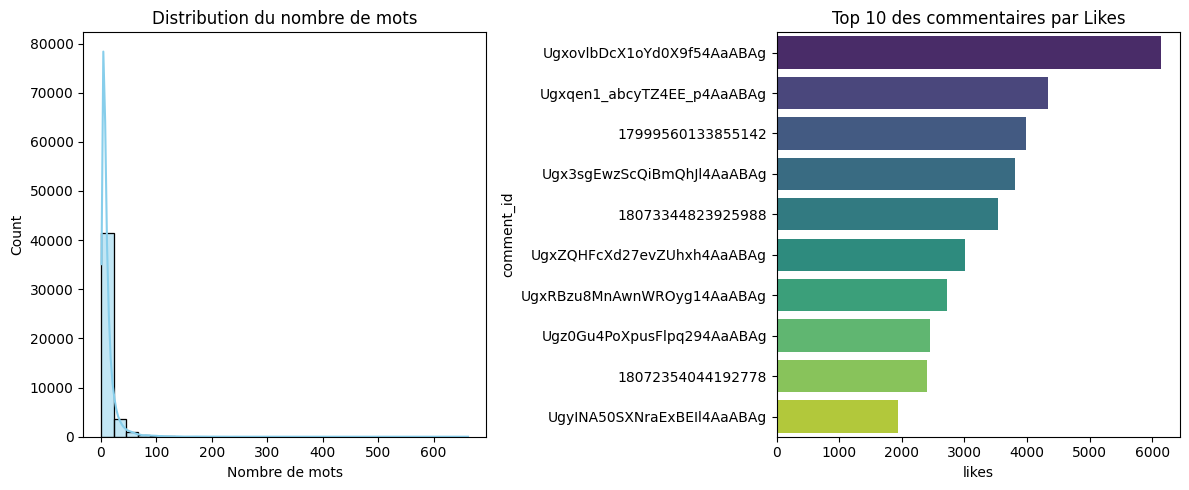

In [4]:
plt.figure(figsize=(12, 5))

# Histogramme de la longueur des mots
plt.subplot(1, 2, 1)
sns.histplot(df['word_count'], bins=30, kde=True, color='skyblue')
plt.title('Distribution du nombre de mots')
plt.xlabel('Nombre de mots')

# Top 10 des commentaires les plus aimés (Likes)
plt.subplot(1, 2, 2)
df_likes = df.nlargest(10, 'likes')
sns.barplot(x='likes', y='comment_id', data=df_likes, palette='viridis')
plt.title('Top 10 des commentaires par Likes')

plt.tight_layout()
plt.show()

#### C. Analyse du vocabulaire (Word Cloud)
Pour visualiser les termes les plus fréquents en Darija, nous utilisons un nuage de mots. 
*Note : Pour l'arabe, nous utilisons `arabic_reshaper` pour l'affichage correct des caractères.*

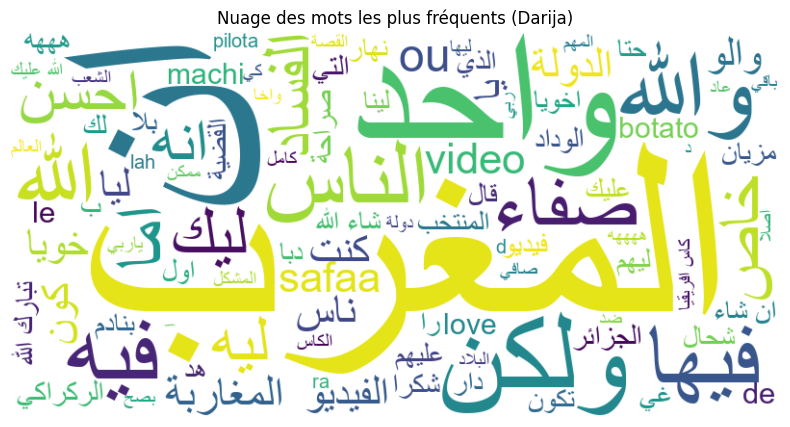

In [5]:
# Concaténer tout le texte
text_global = " ".join(df['text'].astype(str))

# Correction pour l'affichage de l'arabe
reshaped_text = arabic_reshaper.reshape(text_global)
bidi_text = get_display(reshaped_text)

# Génération du nuage de mots
wordcloud = WordCloud(
    font_path='arial.ttf', # Assurez-vous d'avoir un fichier de police arabe ou utilisez le chemin par défaut
    width=800, 
    height=400, 
    background_color='white',
    max_words=100
).generate(bidi_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Nuage des mots les plus fréquents (Darija)')
plt.show()

#### I. Analyse des types d'écriture (Scripts)
La Darija marocaine a la particularité d'être écrite avec deux alphabets différents :
1. **Arabe** : Écriture traditionnelle.
2. **Latin (Arabizi)** : Utilisation des caractères latins et des chiffres (3, 7, 9) pour représenter les sons arabes.
3. **Mixte** : Commentaires utilisant les deux alphabets simultanément.

Cette analyse est cruciale pour adapter nos futurs algorithmes de prétraitement.

📊 Répartition par type d'écriture :
script_type
darija en lettre Arabe    32833
darija Latin (Arabizi)    12140
darijaMixte                1672
Name: count, dtype: int64


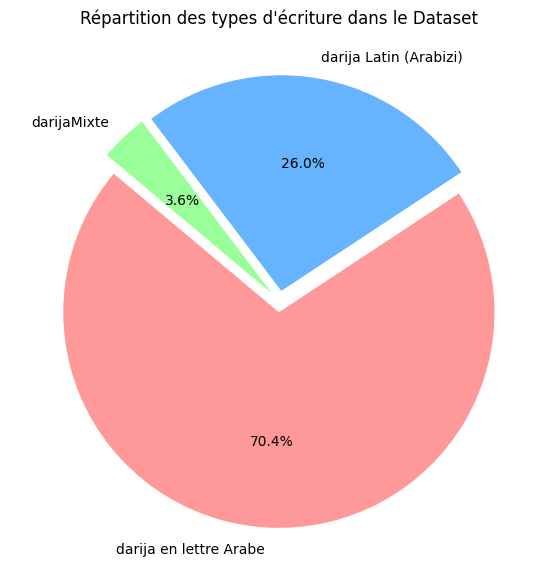

In [9]:
import re
import matplotlib.pyplot as plt

def detect_script(text):
    text = str(text)
    has_arabic = bool(re.search(r'[\u0600-\u06FF]', text))
    has_latin = bool(re.search(r'[a-zA-Z]', text))
    
    if has_arabic and has_latin:
        return 'darijaMixte'
    elif has_arabic:
        return 'darija en lettre Arabe'
    elif has_latin:
        return 'darija Latin (Arabizi)'
    else:
        return 'Autre/Chiffres'

# Application de la détection
df['script_type'] = df['text'].apply(detect_script)

# Calcul des statistiques
script_counts = df['script_type'].value_counts()
print("📊 Répartition par type d'écriture :")
print(script_counts)

# --- CORRECTION ICI ---
# On définit autant de couleurs et d'explosion qu'il y a de catégories réelles
n_categories = len(script_counts)
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99'][:n_categories]
explode = [0.05] * n_categories # On explose chaque part de 0.05

plt.figure(figsize=(10, 7))
plt.pie(
    script_counts, 
    labels=script_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors, 
    explode=explode
)
plt.title('Répartition des types d\'écriture dans le Dataset')
plt.show()

#### J. Comparaison de la longueur selon le type d'écriture
Nous vérifions si les utilisateurs écrivant en Arabizi (Latin) sont plus concis que ceux utilisant l'alphabet Arabe.

C:\Users\DELL\AppData\Local\Temp\ipykernel_23588\4004354363.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='script_type', y='word_count', data=df, palette='Set2')


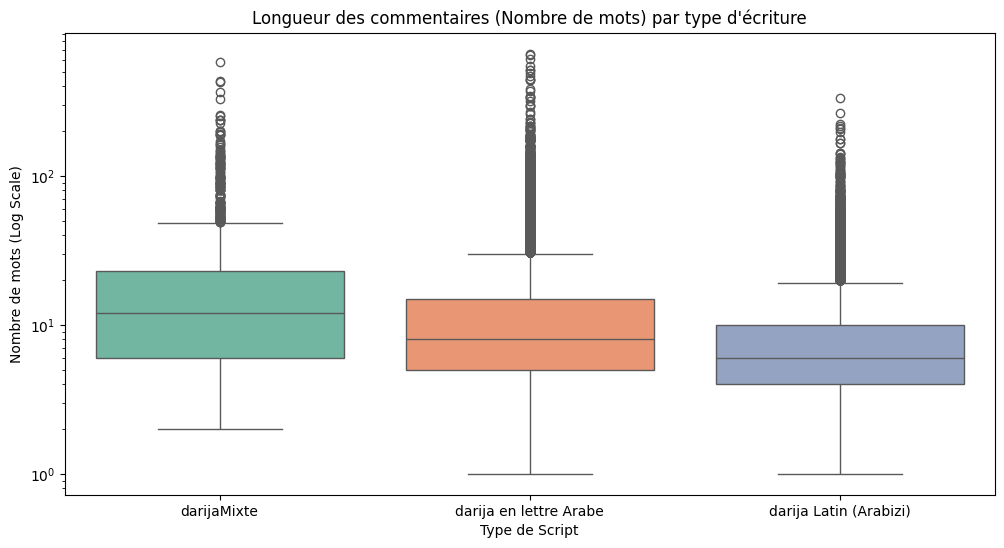

In [10]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='script_type', y='word_count', data=df, palette='Set2')
plt.yscale('log') # Échelle logarithmique si certains commentaires sont très longs
plt.title('Longueur des commentaires (Nombre de mots) par type d\'écriture')
plt.xlabel('Type de Script')
plt.ylabel('Nombre de mots (Log Scale)')
plt.show()

#### F. Analyse de la distribution temporelle
Cette visualisation permet de voir les pics d'activité dans la collecte des données. Nous convertissons le champ `date` pour analyser l'évolution du volume de commentaires par jour ou par mois.

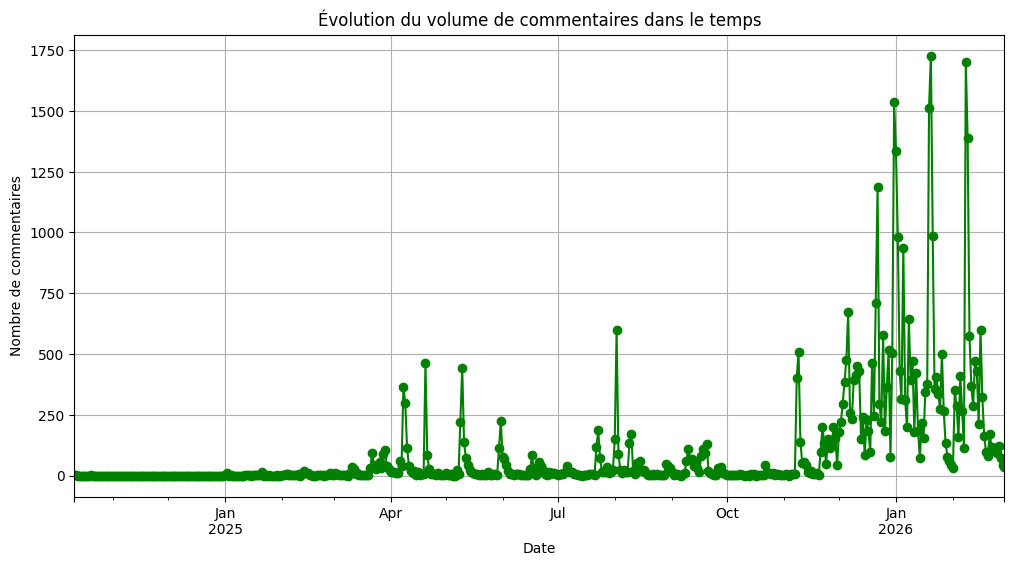

In [13]:
# Conversion de la colonne date en format datetime si ce n'est pas déjà fait
df['date'] = pd.to_datetime(df['date'])

# Groupement par jour
daily_comments = df.resample('D', on='date').count()['comment_id']

plt.figure(figsize=(12, 6))
daily_comments.plot(kind='line', marker='o', color='green', linewidth=1.5)
plt.title('Évolution du volume de commentaires dans le temps')
plt.xlabel('Date')
plt.ylabel('Nombre de commentaires')
plt.grid(True)
plt.show()